[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JeyJey9/credit-card-fraud-detection-dl/blob/main/Credit_Card_Fraud_Detection_DL.ipynb)

# Credit Card Fraud Detection Using Multi-Layer Perceptrons and Focal Loss

- **Author:** George-Cătălin Rece
- **Course:** Advanced Artificial Intelligence and Machine Learning Research (AAIMR) - Prof. Dr. Costin Bădică
- **Project:** Research Project #1 (Section 2.1: Credit Card Fraud Detection)
- **GitHub Repository:** https://github.com/JeyJey9/credit-card-fraud-detection-dl
- **Google Colab Link:** https://colab.research.google.com/github/JeyJey9/credit-card-fraud-detection-dl/blob/main/Credit_Card_Fraud_Detection_DL.ipynb
- **Dataset:** ULB Credit Card Fraud Detection (`mlg-ulb/creditcardfraud`, $284,807$ transactions, $492$ frauds)

## Contents
1. Imports and Setup (`SEED = 42`)
2. Dataset Loading, Exploratory Data Analysis (EDA), and Preprocessing (`RobustScaler`)
3. Binary Focal Loss and `FraudMLP` Network Implementation
4. Training Loop with Validation PR-AUC Early Stopping and Threshold Calibration
5. Training Baseline MLP (BCE), Weighted MLP, and Focal Loss MLP
6. Extension 2: Automated Hyperparameter Tuning with Optuna
7. Extension 3: Comparison with XGBoost on the Held-Out Test Set
8. Extension 1: Model Explainability with SHAP (`GradientExplainer`)

In [1]:
# Install extra packages if running on Google Colab
# !pip install -q optuna shap xgboost

import os
import copy
import math
import time
import json
import random
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_recall_curve,
    roc_curve, f1_score, precision_score, recall_score,
    confusion_matrix, matthews_corrcoef, balanced_accuracy_score, brier_score_loss
)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device} | Seed: {SEED}')

Device: cpu | Seed: 42


## 1. Dataset Loading, Exploratory Data Analysis, and Preprocessing
We download `creditcard.csv` if not already present locally (`284,807` transactions, `492` frauds = `0.1727%`), perform a stratified `70% / 15% / 15%` Train/Val/Test split (`SEED=42`), and fit `RobustScaler` on training `Time` and `Amount`.

Dataset shape: (284807, 31), Frauds: 492 (0.1727%)
Train shape: (199364, 30) (Frauds: 344)
Val shape:   (42721, 30) (Frauds: 74)
Test shape:  (42722, 30) (Frauds: 74)


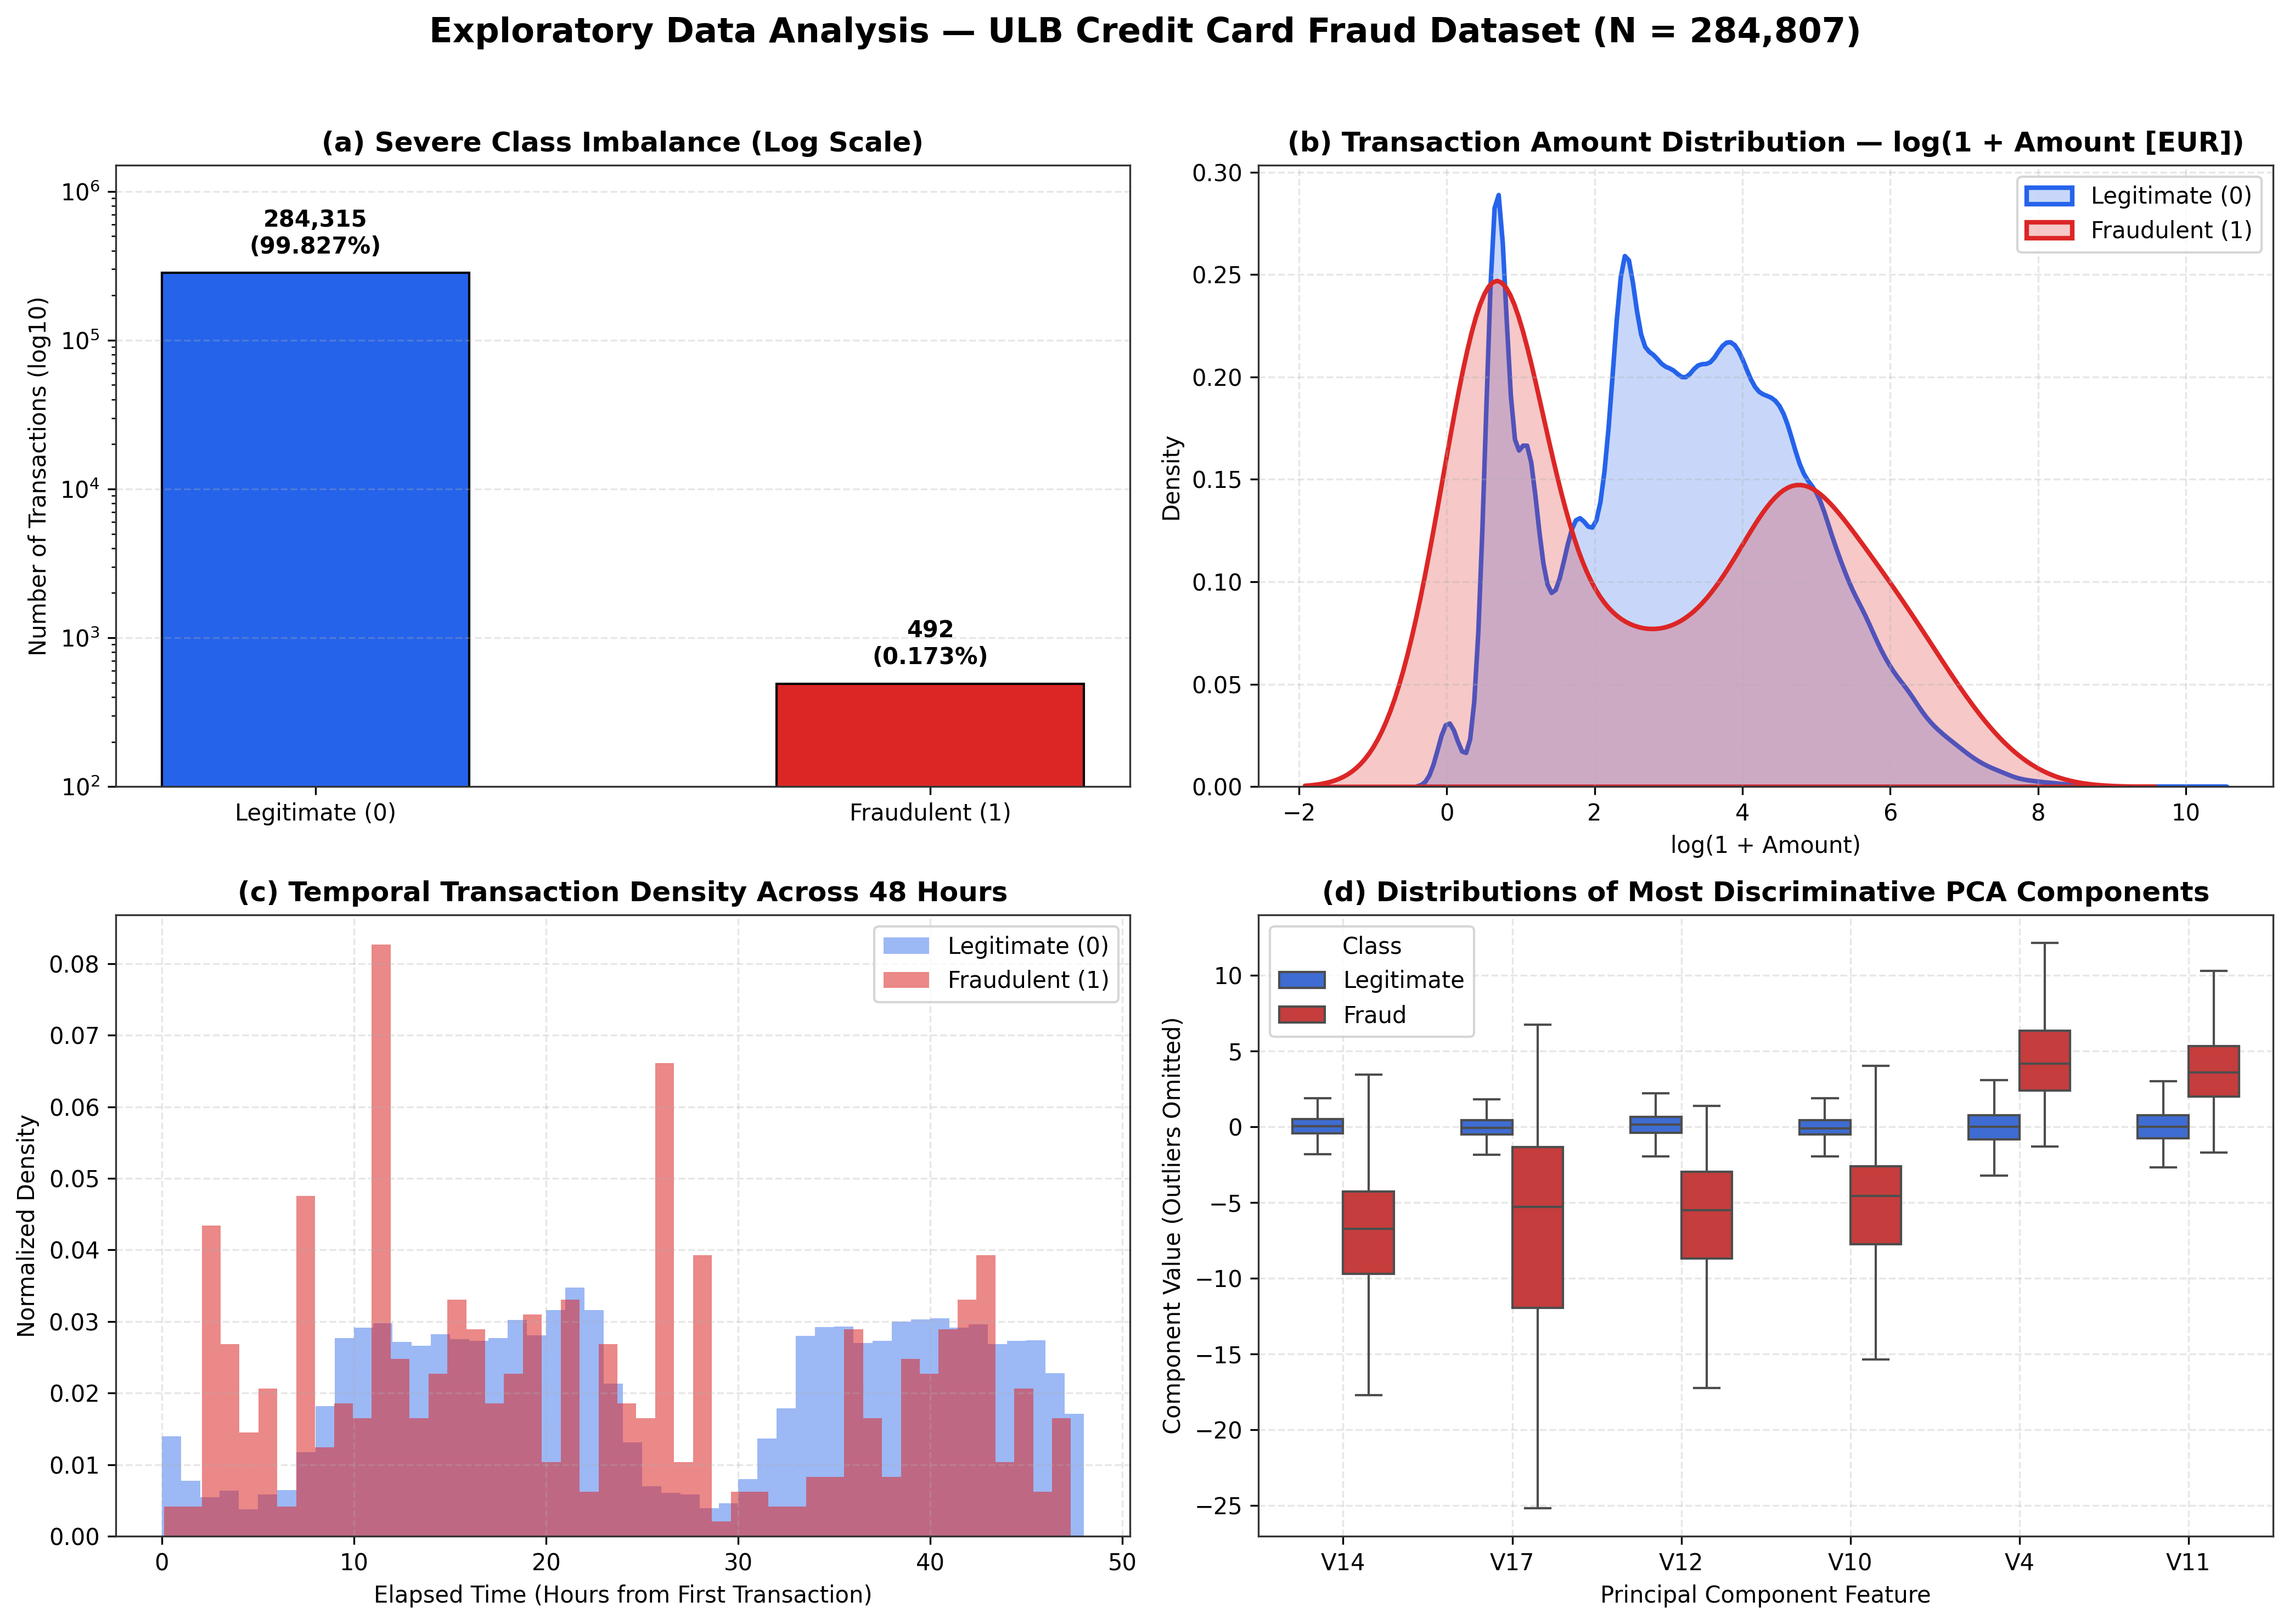

In [2]:
os.makedirs('data', exist_ok=True)
csv_path = 'data/creditcard.csv'
if not os.path.exists(csv_path):
    url = 'https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv'
    urllib.request.urlretrieve(url, csv_path)

df = pd.read_csv(csv_path)
feature_cols = [c for c in df.columns if c != 'Class']
X = df[feature_cols].copy()
y = df['Class'].values.astype(np.int64)

X_temp, X_test_raw, y_temp, y_test = train_test_split(X, y, test_size=0.15, stratify=y, random_state=SEED)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15 / 0.85, stratify=y_temp, random_state=SEED
)

scaler = RobustScaler()
scale_cols = ['Time', 'Amount']
X_train_df, X_val_df, X_test_df = X_train_raw.copy(), X_val_raw.copy(), X_test_raw.copy()
X_train_df[scale_cols] = scaler.fit_transform(X_train_raw[scale_cols])
X_val_df[scale_cols] = scaler.transform(X_val_raw[scale_cols])
X_test_df[scale_cols] = scaler.transform(X_test_raw[scale_cols])

X_train = X_train_df.values.astype(np.float32)
X_val = X_val_df.values.astype(np.float32)
X_test = X_test_df.values.astype(np.float32)

n_neg_train = int((y_train == 0).sum())
n_pos_train = int((y_train == 1).sum())
prior_prob = n_pos_train / float(len(y_train))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train.astype(np.float32))), batch_size=1024, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val.astype(np.float32))), batch_size=2048, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.from_numpy(X_test), torch.from_numpy(y_test.astype(np.float32))), batch_size=2048, shuffle=False)

print(f'Dataset shape: {df.shape}, Frauds: {int(y.sum())} ({100*y.mean():.4f}%)')
print(f'Train shape: {X_train.shape} (Frauds: {n_pos_train})')
print(f'Val shape:   {X_val.shape} (Frauds: {int(y_val.sum())})')
print(f'Test shape:  {X_test.shape} (Frauds: {int(y_test.sum())})')

## 2. Binary Focal Loss and `FraudMLP` Network Implementation
Binary Focal Loss (Lin et al., 2017) [31] adds a modulating term $(1 - p_t)^\gamma$ to reduce the loss contribution of easy negative examples:
$$\text{FL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$
We also initialize the output layer bias to $b_0 = -\log((1 - \pi)/\pi) \approx -6.36$ using the training fraud rate $\pi = 0.001725$.

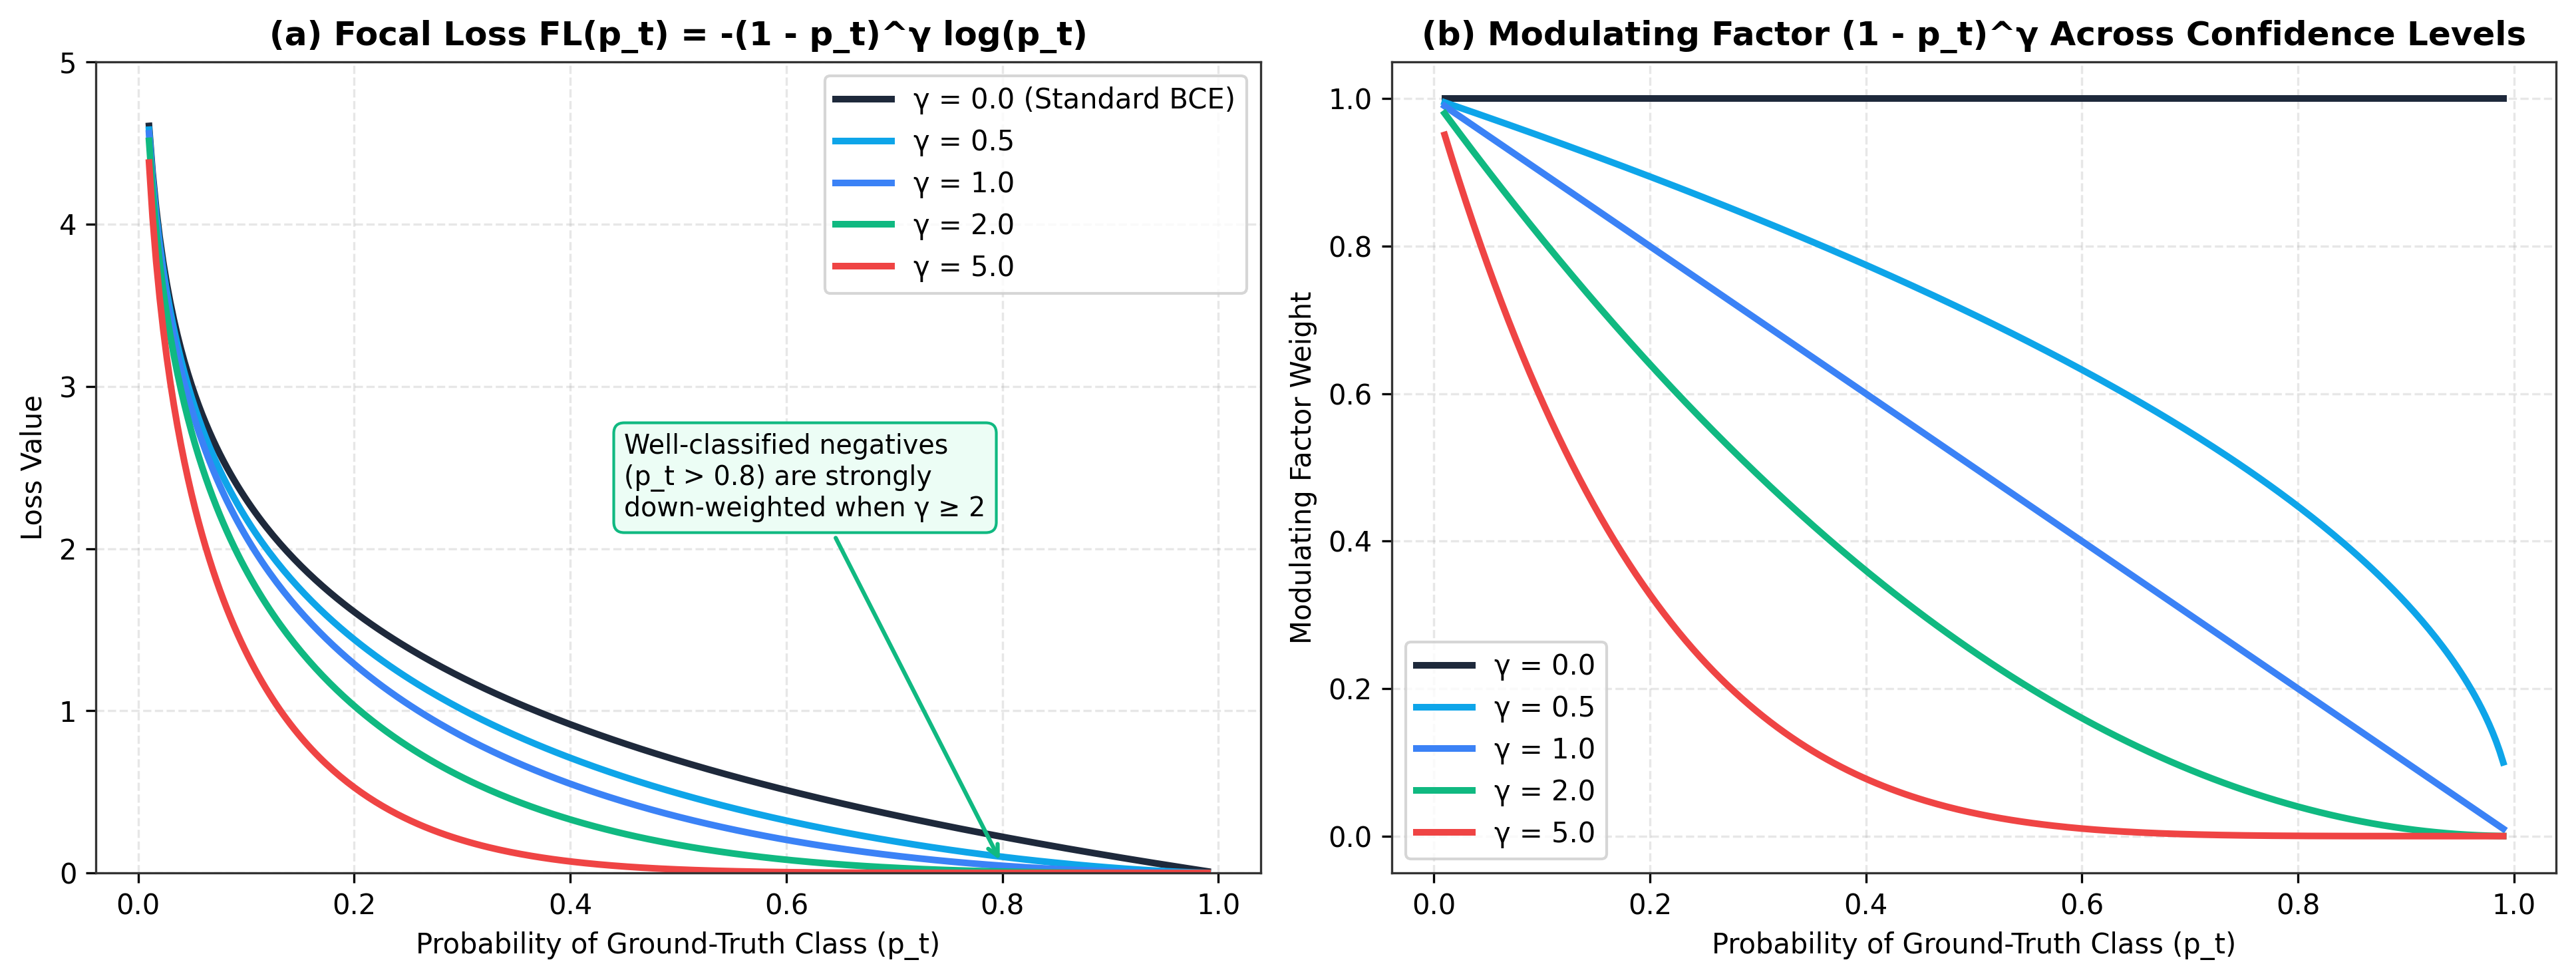

In [3]:
class BinaryFocalLoss(nn.Module):
    def __init__(self, alpha: float = 0.75, gamma: float = 2.0, reduction: str = 'mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        logits = logits.view(-1)
        targets = targets.view(-1).float()
        bce_loss = F.binary_cross_entropy_with_logits(logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1.0 - probs) * (1.0 - targets)
        modulating_factor = torch.pow((1.0 - p_t).clamp(min=1e-8), self.gamma)
        if self.alpha is not None and self.alpha >= 0.0:
            alpha_t = self.alpha * targets + (1.0 - self.alpha) * (1.0 - targets)
            focal_loss = alpha_t * modulating_factor * bce_loss
        else:
            focal_loss = modulating_factor * bce_loss
        return focal_loss.mean() if self.reduction == 'mean' else focal_loss.sum()

ACTIVATIONS = {'relu': nn.ReLU, 'gelu': nn.GELU, 'silu': nn.SiLU}

class FraudMLP(nn.Module):
    def __init__(self, input_dim=30, hidden_dims=(128, 64, 32), dropout=0.3, activation='relu', prior_prob=None):
        super().__init__()
        act_cls = ACTIVATIONS.get(activation.lower(), nn.ReLU)
        layers, in_features = [], input_dim
        for h_dim in hidden_dims:
            layers.extend([nn.Linear(in_features, h_dim), nn.BatchNorm1d(h_dim), act_cls(), nn.Dropout(dropout)])
            in_features = h_dim
        self.feature_extractor = nn.Sequential(*layers)
        self.classifier = nn.Linear(in_features, 1)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
        if prior_prob is not None and 0.0 < prior_prob < 1.0:
            nn.init.constant_(self.classifier.bias, -math.log((1.0 - prior_prob) / prior_prob))

    def forward(self, x):
        return self.classifier(self.feature_extractor(x)).squeeze(-1)

## 3. Training Loop and Evaluation Functions
The MLP models are trained with `AdamW`, gradient clipping ($\le 2.0$), `ReduceLROnPlateau`, and early stopping on Validation PR-AUC.

Model,Val_PR_AUC,Opt_Threshold,Test_PR_AUC,Test_ROC_AUC,Test_F1,Test_Precision,Test_Recall,Test_MCC
Baseline MLP (BCE),0.869764,0.087453,0.840806,0.978912,0.777070,0.734940,0.824324,0.777945
Weighted MLP (Cost-Sensitive),0.786676,0.961029,0.701912,0.981751,0.774648,0.808824,0.743243,0.774968
Focal Loss MLP,0.848451,0.382615,0.826779,0.970595,0.774194,0.740741,0.810811,0.774577
Optuna Focal MLP,0.879789,0.543202,0.827999,0.964890,0.828571,0.878788,0.783784,0.829651
XGBoost (Baseline),0.877484,0.948724,0.842213,0.972583,0.824427,0.947368,0.729730,0.831212


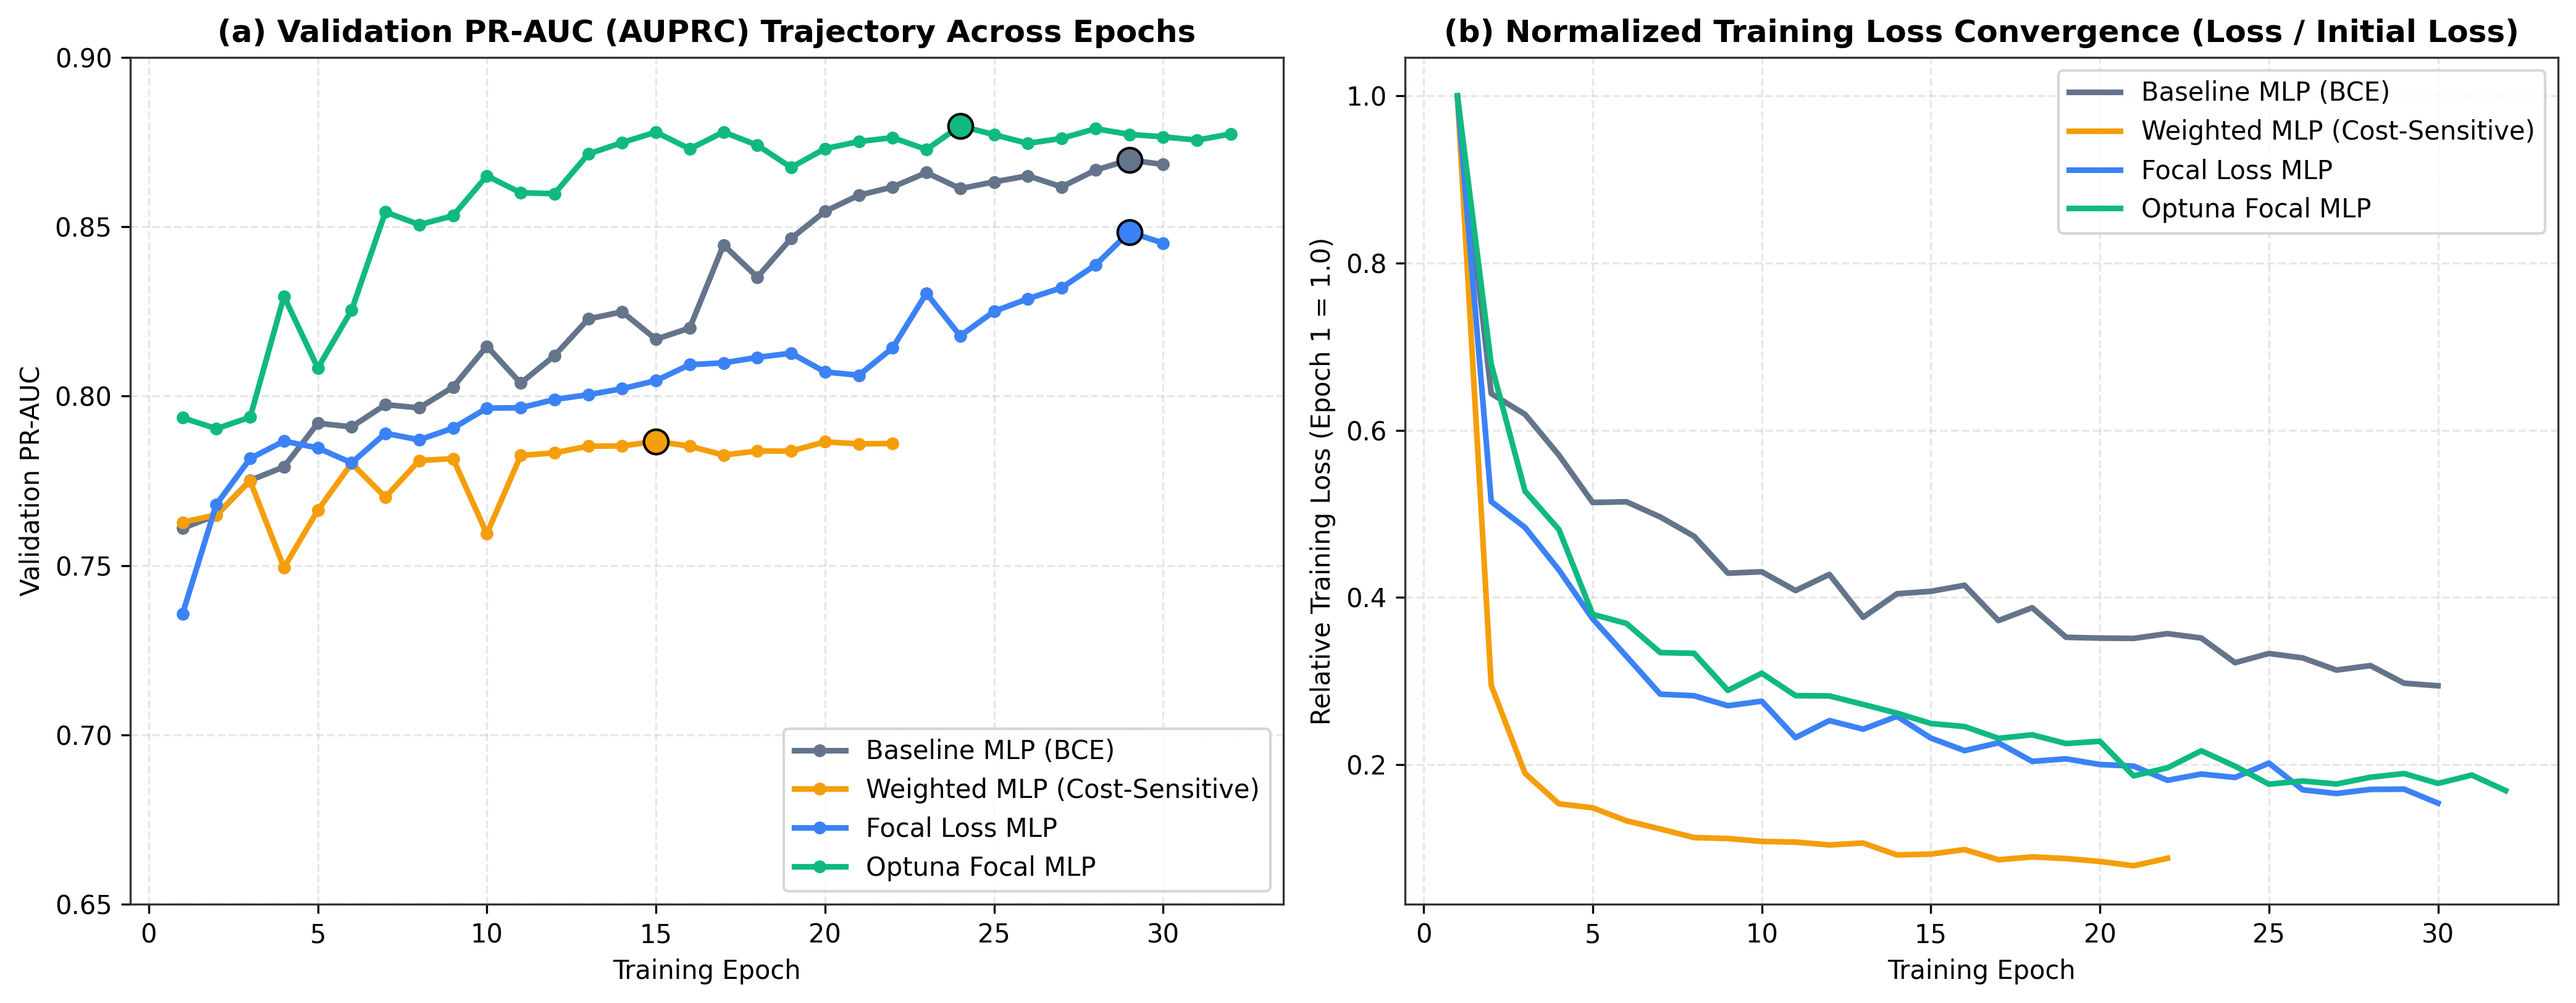

In [4]:
@torch.no_grad()
def predict_dataloader(model, loader, criterion, device):
    model.eval()
    total_loss, n_samples, all_probs, all_targets = 0.0, 0, [], []
    for x_b, y_b in loader:
        x_b, y_b = x_b.to(device), y_b.to(device)
        logits = model(x_b)
        total_loss += criterion(logits, y_b).item() * x_b.size(0)
        n_samples += x_b.size(0)
        all_probs.append(torch.sigmoid(logits).cpu().numpy())
        all_targets.append(y_b.cpu().numpy())
    return total_loss / max(1, n_samples), np.concatenate(all_targets).astype(np.int64), np.concatenate(all_probs)

def find_optimal_threshold(y_true, y_prob):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)
    f1_scores = (2.0 * precisions[:-1] * recalls[:-1]) / np.clip(precisions[:-1] + recalls[:-1], 1e-12, None)
    best_idx = int(np.argmax(f1_scores))
    return float(thresholds[best_idx]), float(f1_scores[best_idx])

def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(np.int64)
    y_pred_05 = (y_prob >= 0.5).astype(np.int64)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        'threshold': float(threshold),
        'pr_auc': float(average_precision_score(y_true, y_prob)),
        'roc_auc': float(roc_auc_score(y_true, y_prob)),
        'f1': float(f1_score(y_true, y_pred, zero_division=0)),
        'f1_at_05': float(f1_score(y_true, y_pred_05, zero_division=0)),
        'precision': float(precision_score(y_true, y_pred, zero_division=0)),
        'recall': float(recall_score(y_true, y_pred, zero_division=0)),
        'mcc': float(matthews_corrcoef(y_true, y_pred)),
        'tp': int(tp), 'fp': int(fp), 'tn': int(tn), 'fn': int(fn)
    }

def train_mlp_model(model, train_loader, val_loader, criterion, lr=1e-3, weight_decay=1e-4, epochs=32, patience=8, verbose=False):
    model, criterion = model.to(device), criterion.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)
    best_val_pr_auc, best_epoch, epochs_no_improve = -1.0, 0, 0
    best_weights = copy.deepcopy(model.state_dict())
    history = {'train_loss': [], 'val_pr_auc': []}
    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, n_samples = 0.0, 0
        for x_b, y_b in train_loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            loss = criterion(model(x_b), y_b)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            optimizer.step()
            running_loss += loss.item() * x_b.size(0)
            n_samples += x_b.size(0)
        _, y_v_true, y_v_prob = predict_dataloader(model, val_loader, criterion, device)
        val_pr_auc = float(average_precision_score(y_v_true, y_v_prob))
        history['train_loss'].append(running_loss / max(1, n_samples))
        history['val_pr_auc'].append(val_pr_auc)
        scheduler.step(val_pr_auc)
        if val_pr_auc > best_val_pr_auc + 1e-5:
            best_val_pr_auc, best_epoch, epochs_no_improve = val_pr_auc, epoch, 0
            best_weights = copy.deepcopy(model.state_dict())
        else:
            epochs_no_improve += 1
        if epochs_no_improve >= patience:
            break
    model.load_state_dict(best_weights)
    history['best_epoch'], history['best_val_pr_auc'] = best_epoch, best_val_pr_auc
    return model, history

# Train Baseline MLP (BCE), Weighted MLP (w+ = 24.05), and Focal Loss MLP (alpha=0.75, gamma=2.0)
set_seed(SEED)
baseline_mlp, hist_base = train_mlp_model(FraudMLP(30, [128, 64, 32], 0.3, 'relu', prior_prob), train_loader, val_loader, nn.BCEWithLogitsLoss())
set_seed(SEED)
w_pos = math.sqrt(n_neg_train / n_pos_train)
weighted_mlp, hist_w = train_mlp_model(FraudMLP(30, [128, 64, 32], 0.3, 'relu', None), train_loader, val_loader, nn.BCEWithLogitsLoss(pos_weight=torch.tensor([w_pos], device=device)))
set_seed(SEED)
focal_mlp, hist_focal = train_mlp_model(FraudMLP(30, [128, 64, 32], 0.3, 'relu', prior_prob), train_loader, val_loader, BinaryFocalLoss(0.75, 2.0))

## 4. Extension 2: Hyperparameter Tuning with Optuna [5]
We run 20 trials of Optuna TPE tuning over the hidden layer sizes, activation function (`relu`, `gelu`, `silu`), dropout rate, learning rate, weight decay, and Focal Loss $(\alpha, \gamma)$.

Best Trial: 17 | Best Val PR-AUC: 0.8811
Best Parameters: {
  "architecture": "256-128-64",
  "activation": "silu",
  "dropout": 0.25,
  "lr": 0.0012047026898516435,
  "weight_decay": 0.0002617985303062432,
  "focal_alpha": 0.65,
  "focal_gamma": 1.75
}


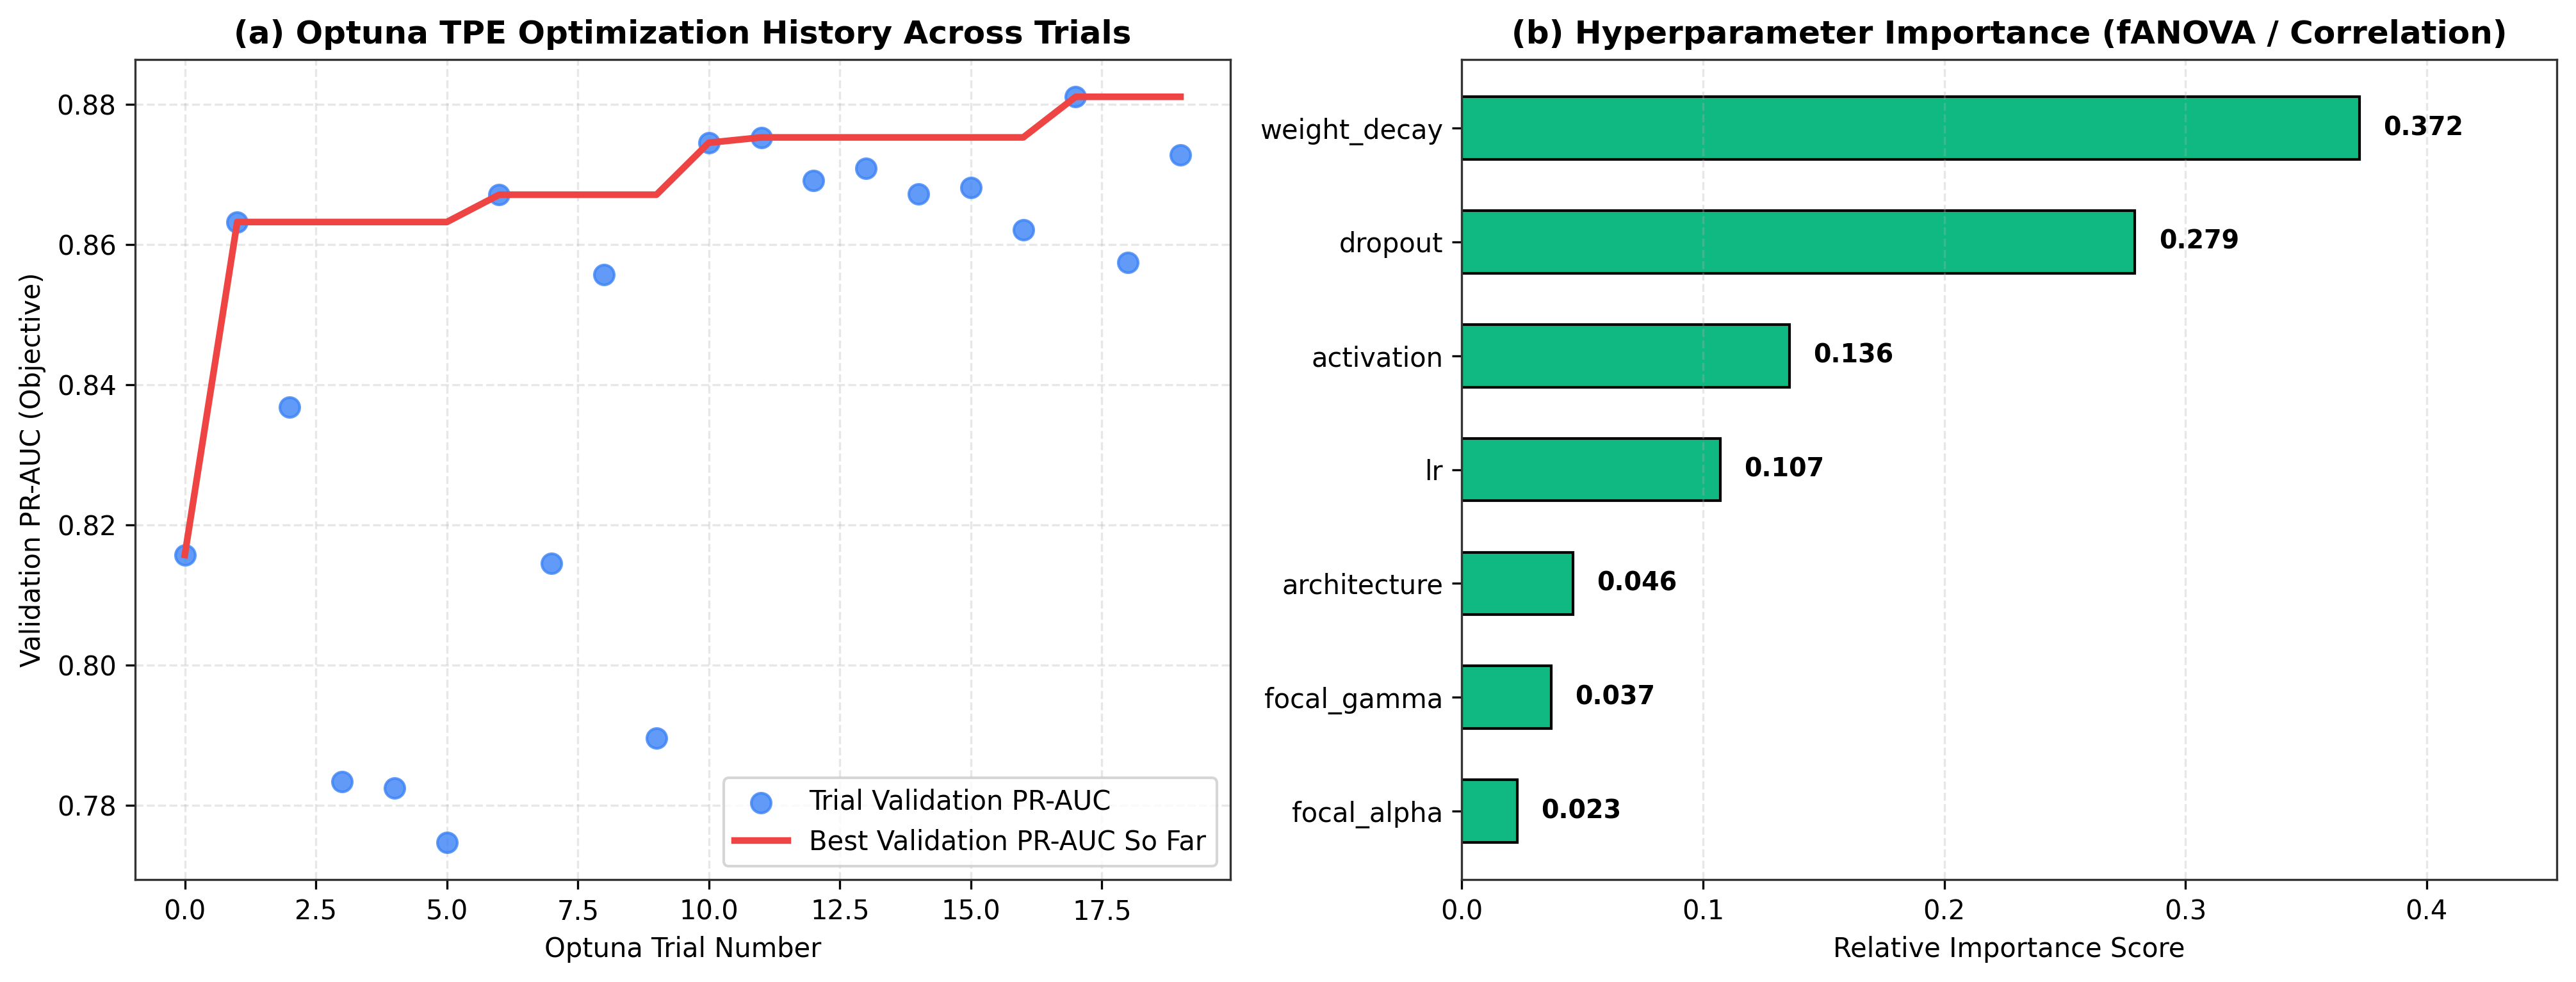

In [5]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

ARCH_SPACE = {'128-64': [128, 64], '128-64-32': [128, 64, 32], '256-128-64': [256, 128, 64], '256-128-64-32': [256, 128, 64, 32]}

def objective(trial):
    set_seed(SEED + trial.number)
    arch_key = trial.suggest_categorical('architecture', list(ARCH_SPACE.keys()))
    activation = trial.suggest_categorical('activation', ['relu', 'gelu', 'silu'])
    dropout = trial.suggest_float('dropout', 0.10, 0.45, step=0.05)
    lr = trial.suggest_float('lr', 3e-4, 3e-3, log=True)
    weight_decay = trial.suggest_float('weight_decay', 1e-5, 1e-3, log=True)
    focal_alpha = trial.suggest_float('focal_alpha', 0.50, 0.90, step=0.05)
    focal_gamma = trial.suggest_float('focal_gamma', 1.0, 3.5, step=0.25)
    m = FraudMLP(30, ARCH_SPACE[arch_key], dropout, activation, prior_prob)
    c = BinaryFocalLoss(focal_alpha, focal_gamma)
    _, h = train_mlp_model(m, train_loader, val_loader, c, lr=lr, weight_decay=weight_decay, epochs=18, patience=5)
    return h['best_val_pr_auc']

study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=20)

best_p = study.best_params
set_seed(SEED)
optuna_mlp, hist_opt = train_mlp_model(
    FraudMLP(30, ARCH_SPACE[best_p['architecture']], best_p['dropout'], best_p['activation'], prior_prob),
    train_loader, val_loader, BinaryFocalLoss(best_p['focal_alpha'], best_p['focal_gamma']),
    lr=best_p['lr'], weight_decay=best_p['weight_decay'], epochs=32, patience=8
)
print('Best Trial:', study.best_trial.number, '| Best Val PR-AUC:', round(study.best_value, 4))
print('Best Parameters:', json.dumps(best_p, indent=2))

## 5. Extension 3: Comparison with XGBoost on the Held-Out Test Set
We train an `XGBClassifier` benchmark on the same data splits and compare all 5 models on the held-out test set ($42,722$ transactions, $74$ frauds).

Model,Test_PR_AUC,Test_F1,Test_F1_at_05,Test_Precision,Test_Recall,TP,FP,TN,FN
Baseline MLP (BCE),0.840806,0.777070,0.800000,0.734940,0.824324,61,22,42626,13
Weighted MLP (Cost-Sensitive),0.701912,0.774648,0.656250,0.808824,0.743243,55,13,42635,19
Focal Loss MLP,0.826779,0.774194,0.770270,0.740741,0.810811,60,21,42627,14
Optuna Focal MLP,0.827999,0.828571,0.845070,0.878788,0.783784,58,8,42640,16
XGBoost (Baseline),0.842213,0.824427,0.848921,0.947368,0.729730,54,3,42645,20


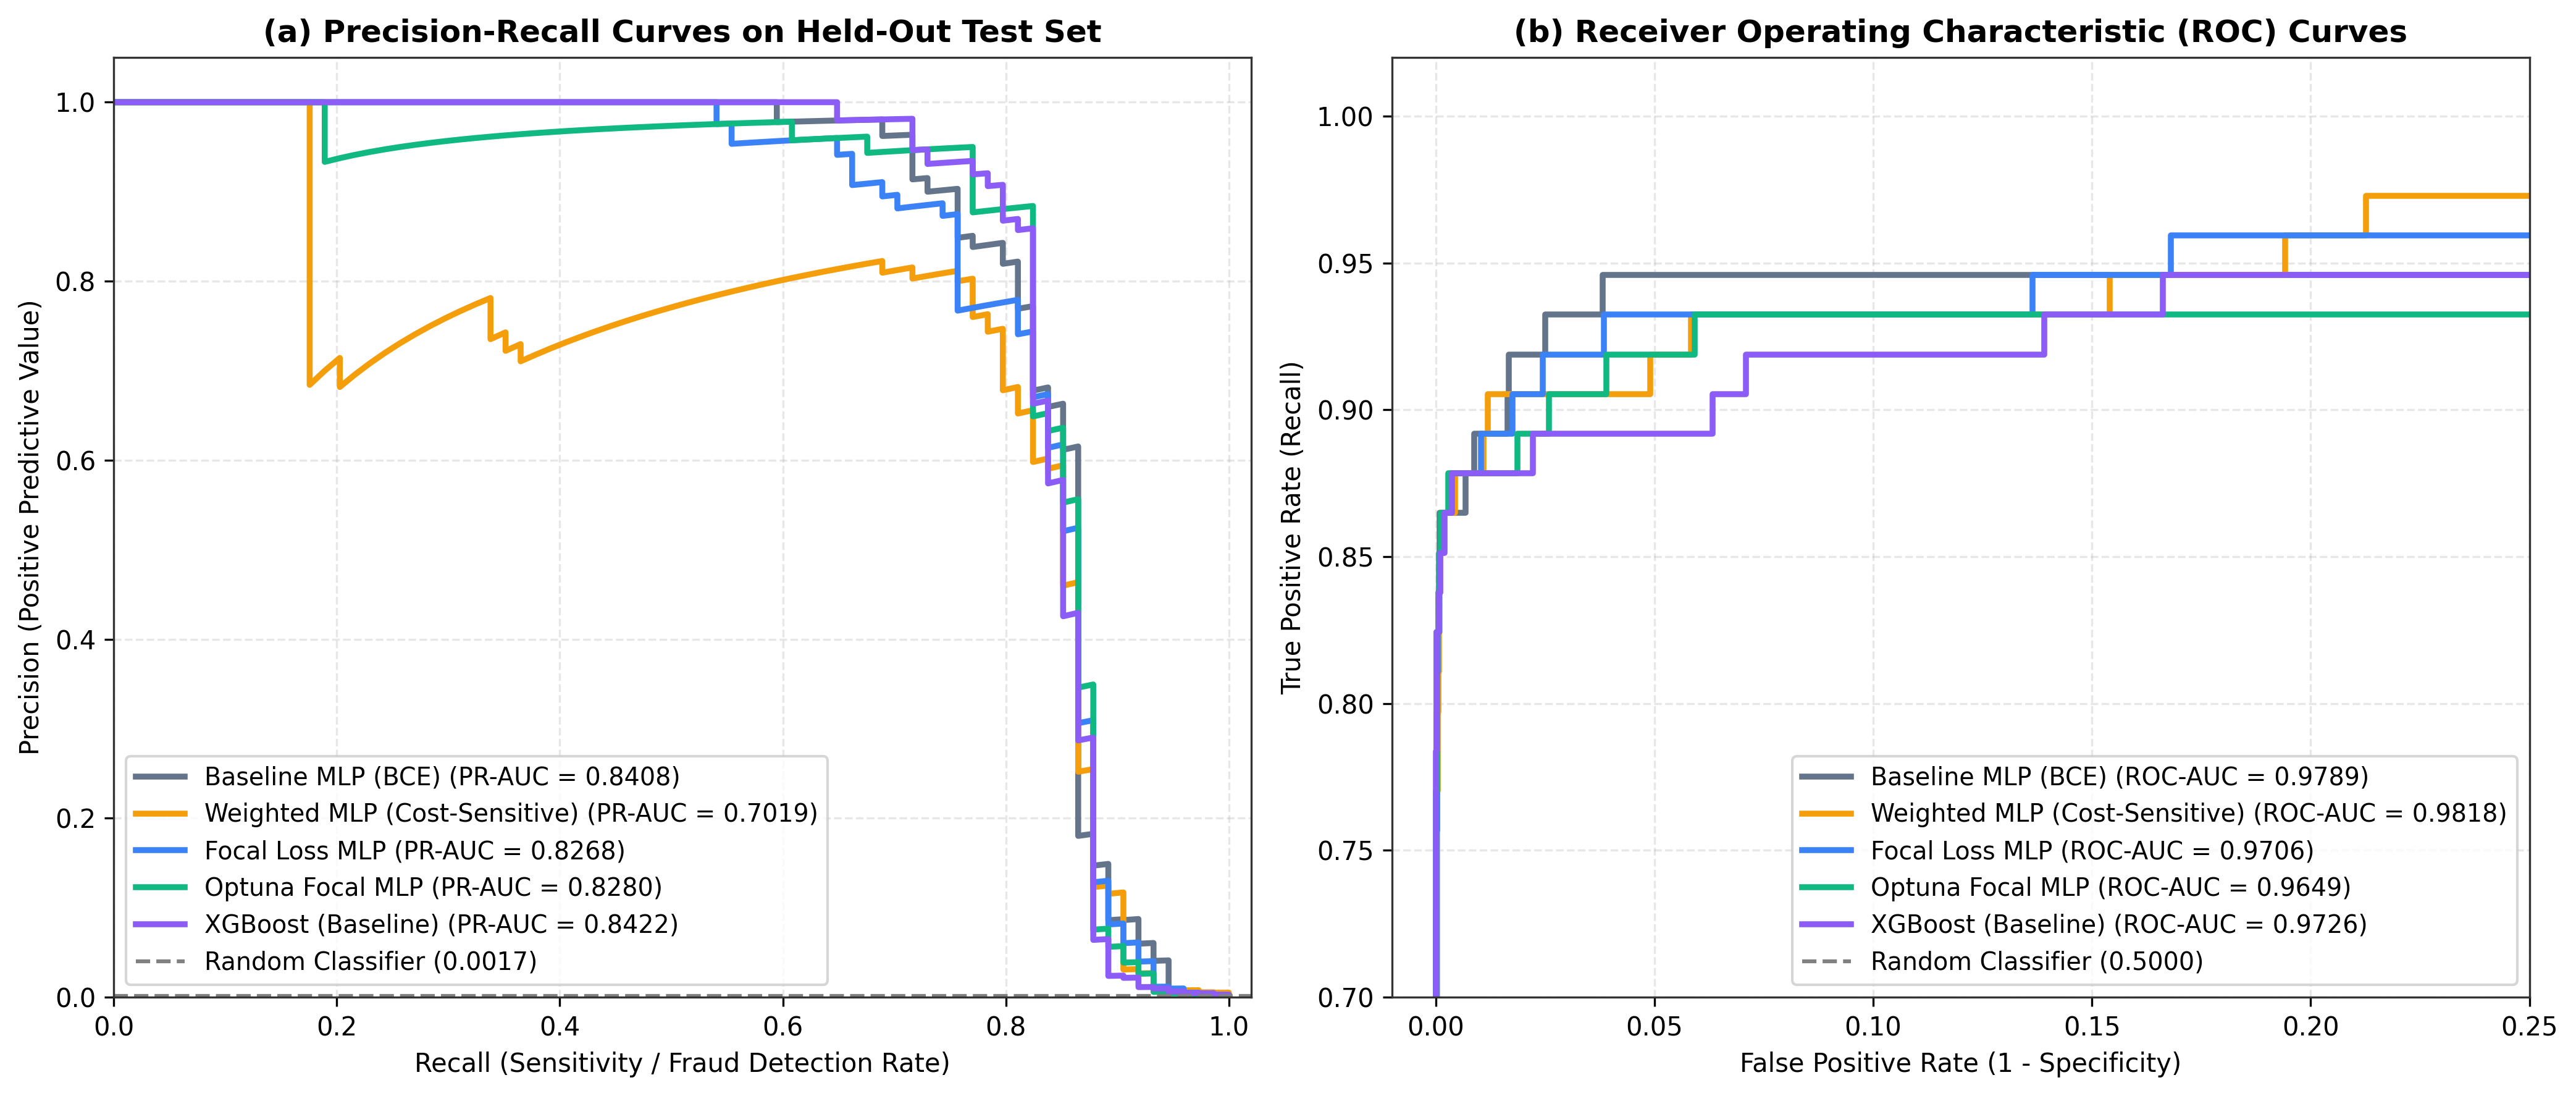

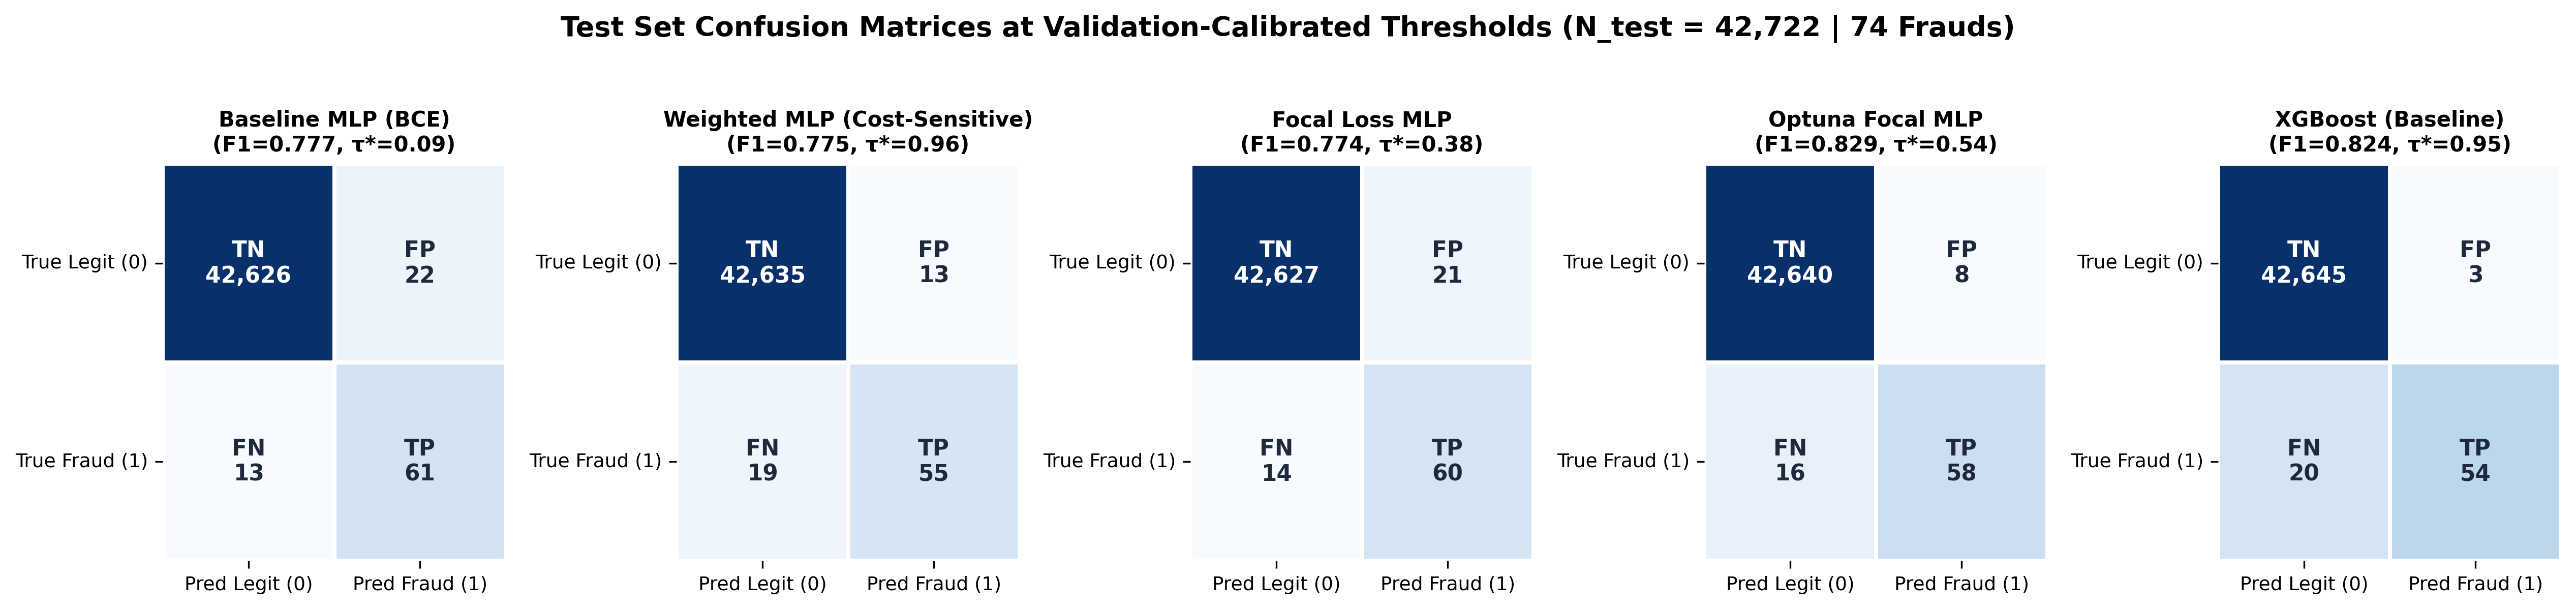

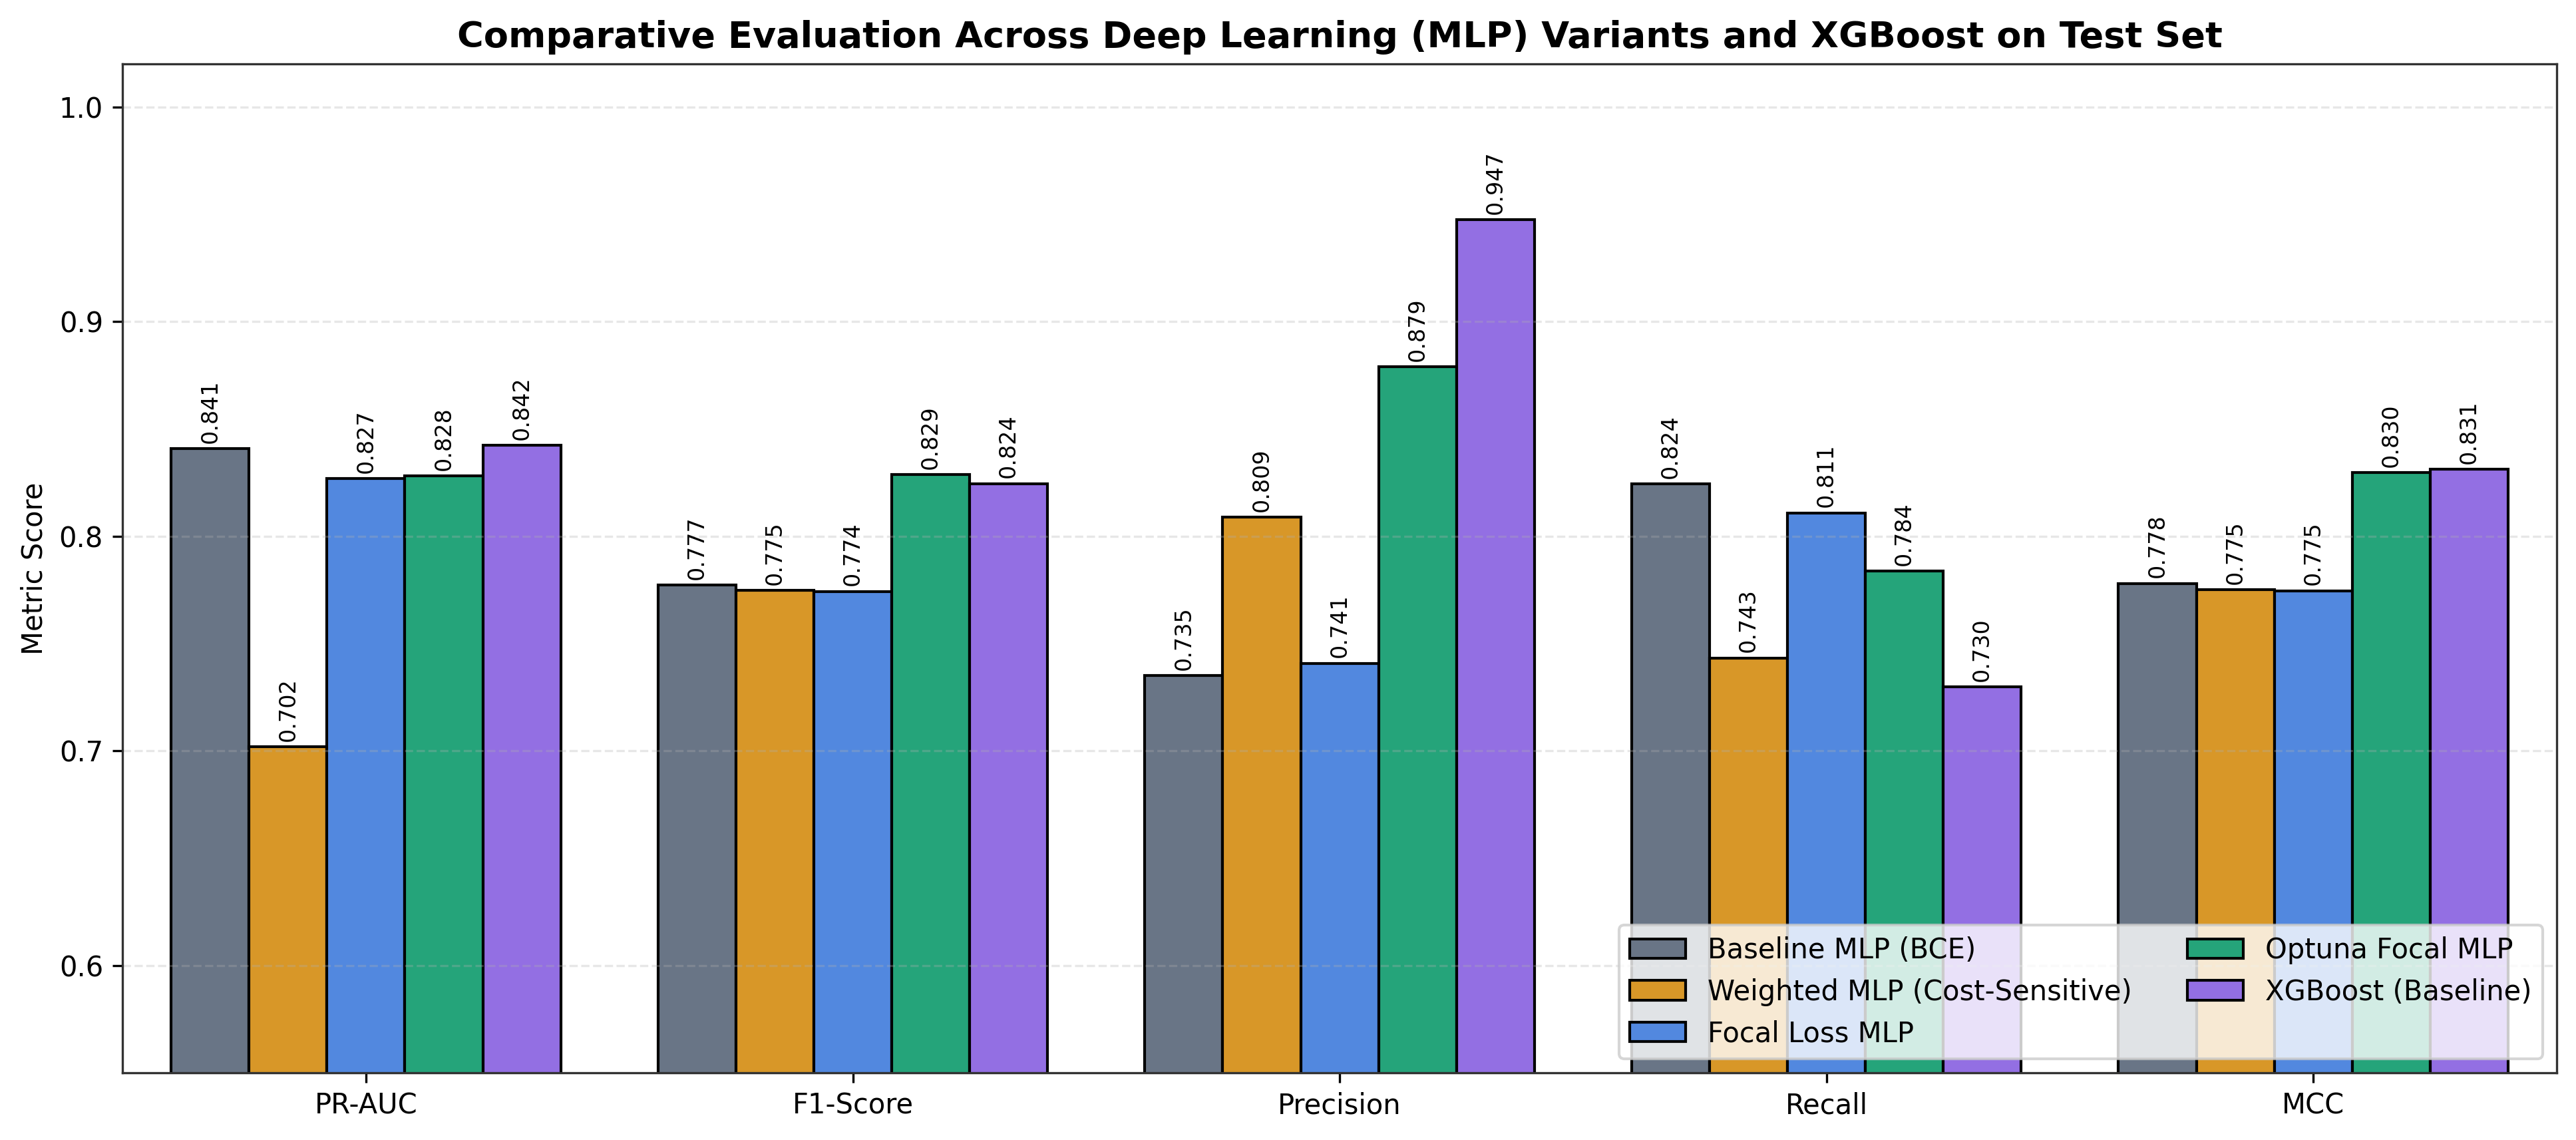

In [6]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=350, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, scale_pos_weight=math.sqrt(n_neg_train / n_pos_train),
    eval_metric='aucpr', early_stopping_rounds=25, random_state=SEED, n_jobs=-1, tree_method='hist'
)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

rows = []
for name, mdl, crit in [
    ('Baseline MLP (BCE)', baseline_mlp, nn.BCEWithLogitsLoss().to(device)),
    ('Weighted MLP (Cost-Sensitive)', weighted_mlp, nn.BCEWithLogitsLoss().to(device)),
    ('Focal Loss MLP (alpha=0.75, gamma=2.0)', focal_mlp, BinaryFocalLoss(0.75, 2.0).to(device)),
    ('Optuna Focal MLP', optuna_mlp, BinaryFocalLoss(best_p['focal_alpha'], best_p['focal_gamma']).to(device)),
]:
    _, yv, pv = predict_dataloader(mdl, val_loader, crit, device)
    _, yt, pt = predict_dataloader(mdl, test_loader, crit, device)
    tau_star, _ = find_optimal_threshold(yv, pv)
    tm = compute_metrics(yt, pt, threshold=tau_star)
    rows.append({'Model': name, 'Test_PR_AUC': round(tm['pr_auc'], 4), 'Test_F1': round(tm['f1'], 4), 'Test_F1_at_05': round(tm['f1_at_05'], 4), 'Test_Precision': round(tm['precision'], 4), 'Test_Recall': round(tm['recall'], 4), 'TP': tm['tp'], 'FP': tm['fp'], 'TN': tm['tn'], 'FN': tm['fn']})

pv_xgb = xgb_model.predict_proba(X_val)[:, 1]
pt_xgb = xgb_model.predict_proba(X_test)[:, 1]
tau_xgb, _ = find_optimal_threshold(y_val, pv_xgb)
tm_xgb = compute_metrics(y_test, pt_xgb, threshold=tau_xgb)
rows.append({'Model': 'XGBoost (Baseline)', 'Test_PR_AUC': round(tm_xgb['pr_auc'], 4), 'Test_F1': round(tm_xgb['f1'], 4), 'Test_F1_at_05': round(tm_xgb['f1_at_05'], 4), 'Test_Precision': round(tm_xgb['precision'], 4), 'Test_Recall': round(tm_xgb['recall'], 4), 'TP': tm_xgb['tp'], 'FP': tm_xgb['fp'], 'TN': tm_xgb['tn'], 'FN': tm_xgb['fn']})

summary_df = pd.DataFrame(rows)
summary_df

## 6. Extension 1: Explainable AI with SHAP [32]
We compute SHAP values (`shap.GradientExplainer`) on the trained **Optuna Focal MLP** to inspect global feature importance and individual transaction predictions.

Feature,Mean_Abs_SHAP,Mean_SHAP_Fraud,Mean_SHAP_Legit
V14,1.219167,3.090611,-0.411605
V4,0.960011,1.380965,-0.218748
V10,0.881607,1.746269,-0.223643
V3,0.373618,-0.080108,0.088065
V12,0.349626,-0.343210,0.039782
V1,0.287799,0.078320,-0.021291
V16,0.284252,0.460900,-0.030924
V9,0.275974,0.429749,-0.037922
V17,0.266783,-0.276854,0.023326
V8,0.253810,0.035788,-0.001250


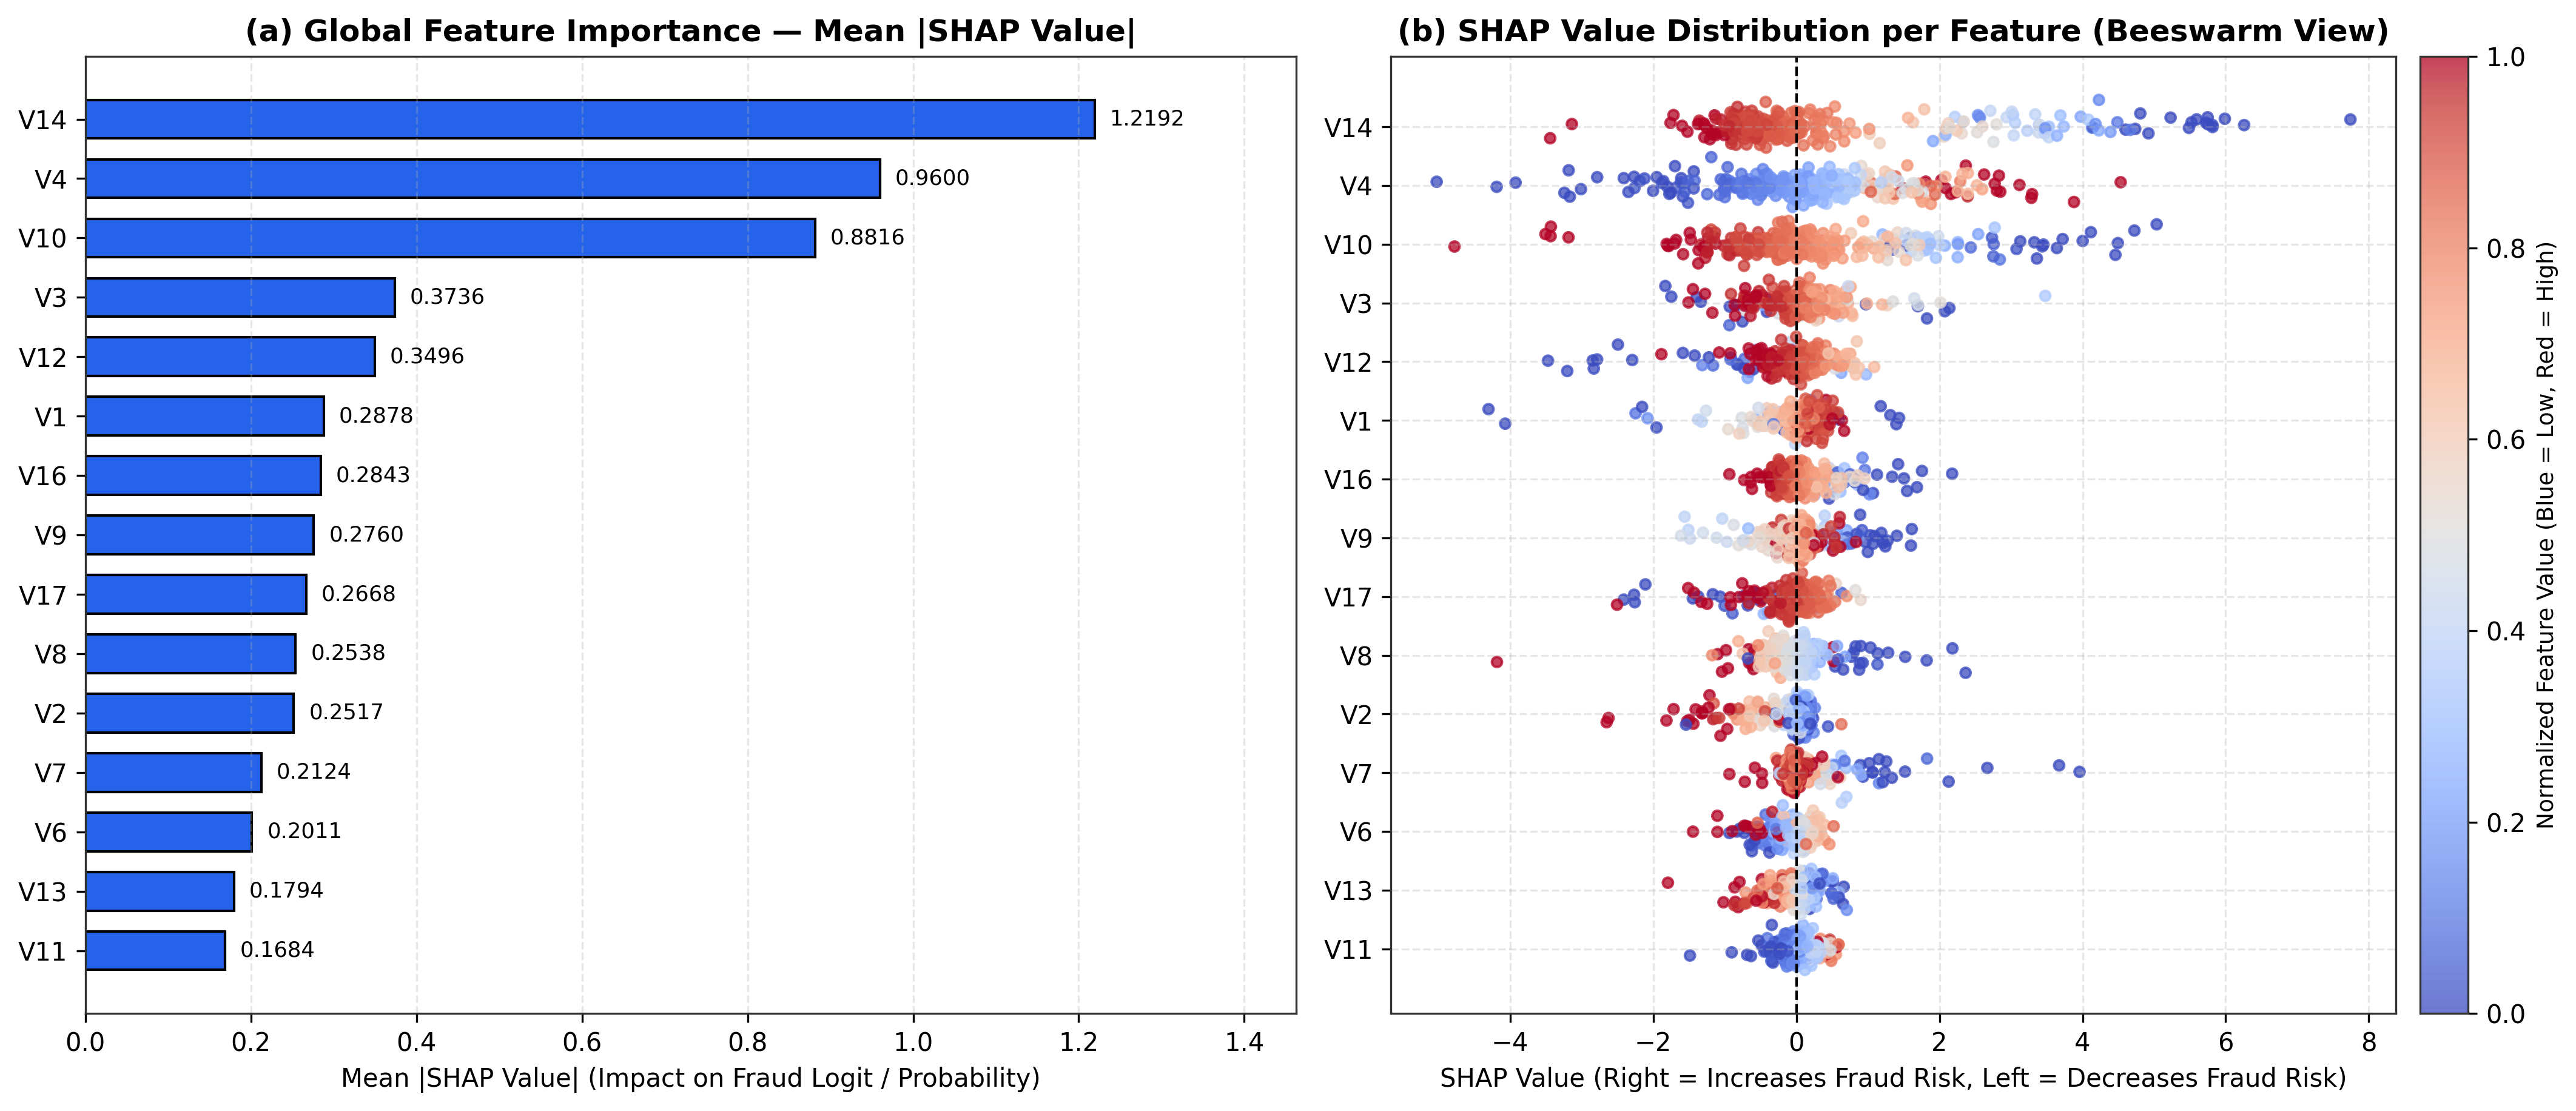

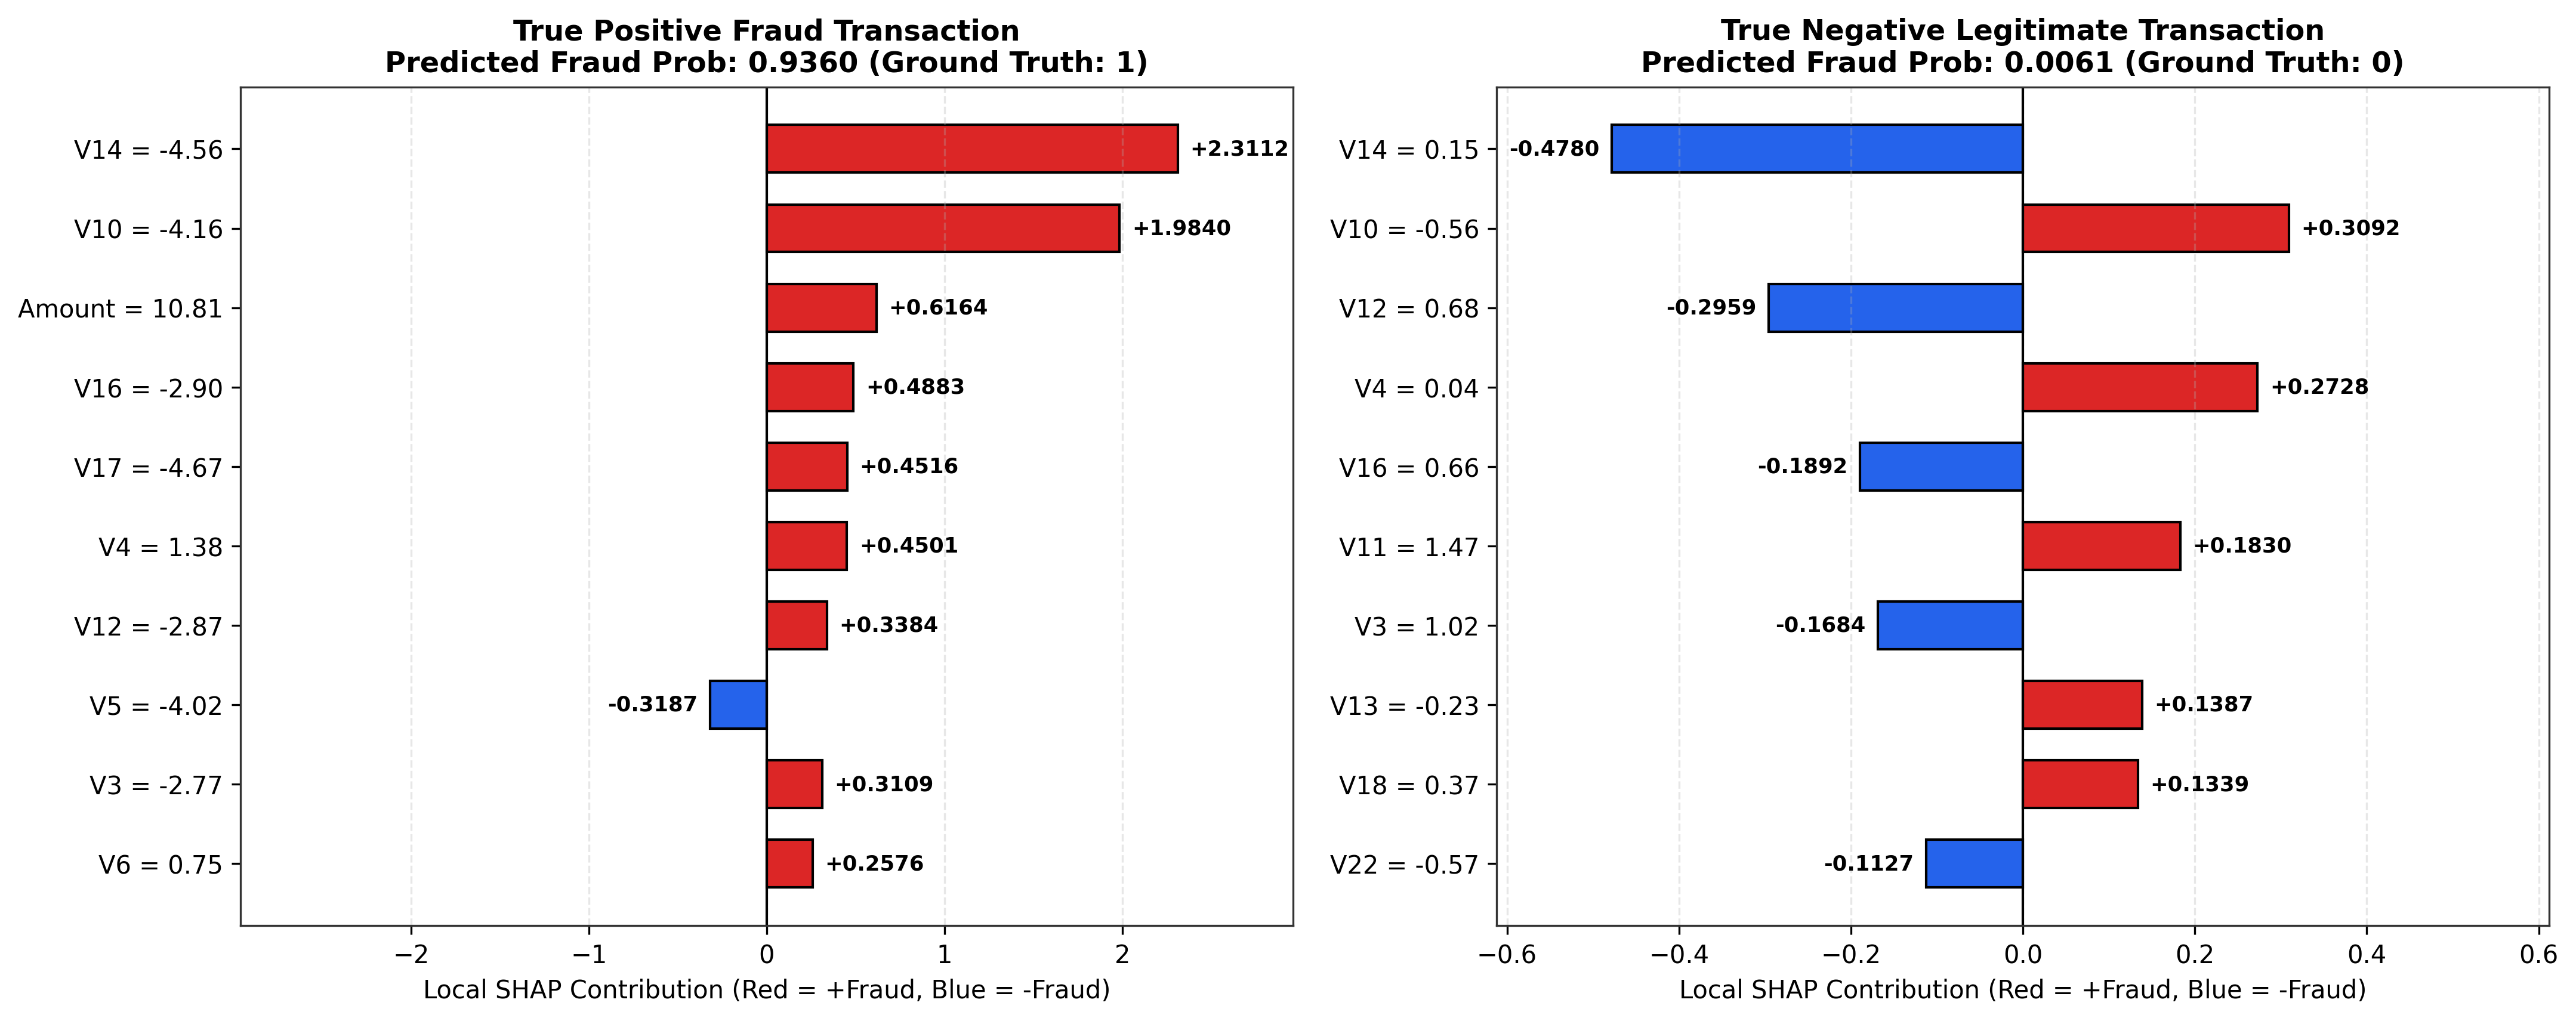

In [7]:
import shap

class ModelWrapper(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model = base_model
    def forward(self, x):
        return self.base_model(x).unsqueeze(-1)

wrapped_model = ModelWrapper(optuna_mlp).to(device).eval()
bg_idx = np.concatenate([np.where(y_train == 0)[0][:180], np.where(y_train == 1)[0][:20]])
explain_idx = np.concatenate([np.where(y_test == 1)[0], np.where(y_test == 0)[0][:226]])

explainer = shap.GradientExplainer(wrapped_model, torch.from_numpy(X_train[bg_idx]).to(device))
shap_vals = explainer.shap_values(torch.from_numpy(X_test[explain_idx]).to(device))
if isinstance(shap_vals, list):
    shap_vals = shap_vals[0]
if shap_vals.ndim == 3:
    shap_vals = shap_vals[:, :, 0]

mean_abs_shap = np.abs(shap_vals).mean(axis=0)
shap_df = pd.DataFrame({'Feature': feature_cols, 'Mean_Abs_SHAP': mean_abs_shap}).sort_values('Mean_Abs_SHAP', ascending=False)
shap_df.head(12)